# 02 Feature engineering (member B)

Feature steps live in `src/features.py`. Use this notebook to:
1. Check that each step produces the right output
2. Try new features
3. Run the ablation to answer "which feature engineering was most useful?"

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # so the notebook can import src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import FIGURE_DIR, TARGET
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

In [2]:
from src.data import load_data
from src.features import STEPS, build_features
train, test = load_data()
print("Available steps:", list(STEPS))

Available steps: ['fix_types', 'fill_missing', 'encode_ordinal', 'add_features', 'add_interactions', 'fix_skew']


## 1. Check step by step

In [3]:
steps = []
for name in STEPS:
    steps.append(name)
    X_tr, X_te = build_features(train, test, steps)
    print(f"{' + '.join(steps):<70} -> {X_tr.shape[1]} features, NaN={X_tr.isna().sum().sum()}")

fix_types                                                              -> 315 features, NaN=0
fix_types + fill_missing                                               -> 330 features, NaN=0
fix_types + fill_missing + encode_ordinal                              -> 290 features, NaN=0
fix_types + fill_missing + encode_ordinal + add_features               -> 301 features, NaN=0
fix_types + fill_missing + encode_ordinal + add_features + add_interactions -> 303 features, NaN=0
fix_types + fill_missing + encode_ordinal + add_features + add_interactions + fix_skew -> 303 features, NaN=0


In [4]:
# How do the new features relate to price?
X_tr, _ = build_features(train, test, ["fix_types", "fill_missing", "encode_ordinal", "add_features"])
new = ["TotalSF", "TotalBath", "HouseAge", "RemodAge", "TotalPorchSF"]
X_tr[new].corrwith(np.log1p(train[TARGET])).sort_values(ascending=False)

TotalSF         0.777297
TotalBath       0.673011
TotalPorchSF    0.398387
RemodAge       -0.568149
HouseAge       -0.587290
dtype: float64

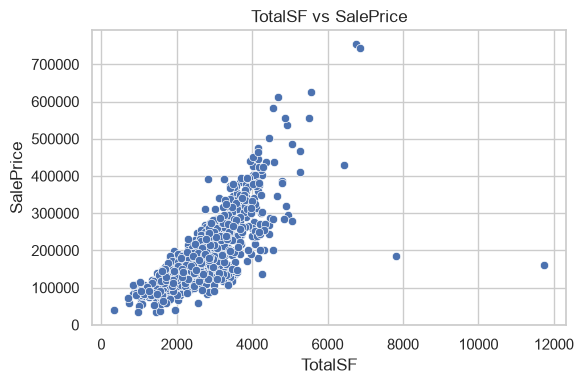

In [5]:
plt.figure(figsize=(6, 4))
sns.scatterplot(x=X_tr["TotalSF"], y=train[TARGET])
plt.title("TotalSF vs SalePrice"); plt.tight_layout(); plt.savefig(FIGURE_DIR / "totalsf_vs_price.png", dpi=150)

## 2. Try new features

Try them here first. If one helps, move it into `src/features.py` (as a new function added to `STEPS`), then add it to iter3 in `versions.py`.

In [6]:
# Example:
# def add_my_feature(df):
#     df = df.copy()
#     df["QualxArea"] = df["OverallQual"] * df["GrLivArea"]
#     return df

## 3. Ablation: which step helps most?

Bigger `delta` = score gets worse when removed = more important step. Also saved to `reports/ablation_log.csv`.

In [7]:
from src.pipeline import ablation
result = ablation("iter3_features")
result

[iter3_features] full CV (all) = 0.12671 | normal = 0.11427
  without encode_ordinal   CV (all) = 0.12612 (-0.00059) | normal = 0.11320 (-0.00107)
  without add_features     CV (all) = 0.12695 (+0.00024) | normal = 0.11491 (+0.00064)
  without add_interactions CV (all) = 0.12647 (-0.00024) | normal = 0.11396 (-0.00030)
  without fix_skew         CV (all) = 0.13835 (+0.01164) | normal = 0.11438 (+0.00011)


,version,removed_step,cv_rmse,delta,cv_rmse_normal,delta_normal
2,iter3_features,add_features,0.12695,0.00024,0.11491,0.00064
4,iter3_features,fix_skew,0.13835,0.01164,0.11438,0.00011
0,iter3_features,(none),0.12671,0.00000,0.11427,0.00000
3,iter3_features,add_interactions,0.12647,-0.00024,0.11396,-0.00030
1,iter3_features,encode_ordinal,0.12612,-0.00059,0.11320,-0.00107


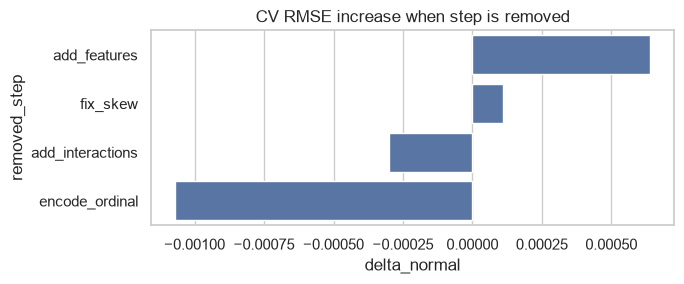

In [8]:
r = result[result.removed_step != "(none)"]
plt.figure(figsize=(7, 3)); sns.barplot(data=r, x="delta_normal", y="removed_step")
plt.title("CV RMSE increase when step is removed"); plt.tight_layout()
plt.savefig(FIGURE_DIR / "ablation.png", dpi=150)

## Conclusion (for the report: most useful feature engineering + why)

- 